# **Exercicio Duelo de Modelos 4**

Nesta tarefa, vocês irão criar o seu próprio duelo de modelos, com o objetivo de superar os resultados apresentados em aula. O desafio é alcançar um desempenho superior ao que obtivemos, e para isso, será necessário aplicar todas as melhorias que vocês aprenderam ao longo dos módulos, utilizando a base de dados do Titanic.

**1. Escolha do Modelo:**
Selecione um dos modelos que foram explorados nos duelos de modelos ao longo do curso. Pode ser SVM, Random Forest, XGBoost, ou qualquer outro que tenhamos abordado.

**2. Aperfeiçoamento:**
**Aplique as técnicas que aprendemos para melhorar o desempenho do seu modelo:**

**Hiperparâmetros:** Utilize GridSearchCV ou RandomSearchCV para encontrar os melhores parâmetros.

**Cross Validation:** Avalie a robustez do modelo utilizando validação cruzada para garantir que ele generaliza bem.

**Balanceamento de Classes:** Se o seu modelo lida com problemas de classes desbalanceadas, explore técnicas como SMOTE, undersampling ou oversampling.

**Padronização e Normalização:** Lembre-se de padronizar os dados, especialmente se for usar modelos que são sensíveis à escala das variáveis.

**3. Submissão no Kaggle:**
Treine o seu modelo com os dados de treino e gere as previsões para os dados de teste. Lembre-se de que o conjunto de teste não possui a variável alvo (y_test), pois a avaliação será feita com base nas submissões no Kaggle.
Submeta suas previsões na competição do Titanic no Kaggle.

**4. Entrega:**
Envie o código que você desenvolveu, detalhando cada etapa do seu processo de modelagem, explicando as escolhas feitas e como essas ajudaram a melhorar o modelo.

Junto com o código, envie um print do seu score obtido na plataforma do Kaggle. Esse score será a sua métrica final de avaliação, mostrando como o seu modelo se compara com os demais.

**5. Competição Saudável:**
A ideia é trazer um senso de competição saudável, então não vale replicar exatamente o que fizemos na aula! Inove, explore novas combinações de parâmetros e técnicas, e mostre do que é capaz. O importante é exercitar o pensamento crítico e a capacidade de experimentar.

**Dicas Finais:**

Seja criativo e tenha um olhar crítico sobre o que pode ser melhorado.
Teste diferentes abordagens e não se prenda a um único caminho.
Lembre-se de que, mais do que alcançar o melhor score, o objetivo é aprender e aplicar o conhecimento de forma prática e eficaz.
Boa sorte! Estamos ansiosos para ver como cada um de vocês vai se sair nesse desafio e quais insights irão surgir dessa competição!

Ao final dessa atividade vocês terão participado da primeira competição publica de ciência de dados de vocês = )




## 1 - Importação das Bibliotecas e carregamento da base de dados

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [139]:
# Carregamento das bases de dados de treino e teste
train_df = pd.read_csv('train.csv')
teste_df = pd.read_csv('test.csv')

In [140]:
# Exibição da base treino com a variável target
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [141]:
# Exibição da base teste que possue somente as features
teste_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 2 - Análise e tratamento dos dados

### A) Tipo de dados

In [151]:
# Análise dos tipos de dados da base de treino
train_df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C        bool
Embarked_Q        bool
Embarked_S        bool
Cabin_A           bool
Cabin_B           bool
Cabin_C           bool
Cabin_D           bool
Cabin_E           bool
Cabin_F           bool
Cabin_G           bool
Cabin_T           bool
Cabin_U           bool
dtype: object

In [152]:
# Análise dos tipos de dados da base de teste
teste_df.dtypes

PassengerId      int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C        bool
Embarked_Q        bool
Embarked_S        bool
Cabin_A           bool
Cabin_B           bool
Cabin_C           bool
Cabin_D           bool
Cabin_E           bool
Cabin_F           bool
Cabin_G           bool
Cabin_U           bool
dtype: object

As bases de dados de treino e teste apresentam estruturas e tipos de dados consistentes, divergindo exclusivamente pela presença da variável alvo (**target**) "`Survived`", contida apenas no conjunto de treino conforme as especificações do desafio.

A análise exploratória inicial identificou cinco variáveis qualitativas (do tipo **object**): `Name`, `Sex`, `Ticket`, `Cabin` e `Embarked`. As variáveis estritamente textuais — `Name` e `Ticket` — serão descartadas nesta etapa de modelagem. Por funcionarem essencialmente como identificadores de texto sem padrão estatístico direto, a permanência delas geraria ruído e não agregaria poder de generalização para os algoritmos.

Para o tratamento das variáveis categóricas remanescentes, foram adotadas abordagens distintas com base em suas características:
- `Sex`: Sendo uma variável binária (duas categorias), será transformada via Label Encoding, mapeando-a diretamente para valores 0 e 1.
- `Embarked`: Por apresentar três categorias distintas, será tratada com One-Hot Encoding (codificação binária dummy), evitando que o modelo presuma uma ordem hierárquica inexistente entre os portos de embarque.
- `Cabin`: Devido ao grande volume de dados nulos e alta fragmentação, aplicou-se uma técnica de engenharia de recursos para extrair a letra inicial de cada registro, que corresponde ao convés ocupado pelo passageiro. Posteriormente, essa nova estrutura será codificada via One-Hot Encoding, permitindo que o modelo capture o impacto da localização espacial no navio sobre a taxa de sobrevivência, sem perda drástica de representatividade dos dados.

In [153]:
# Exclusão das variáveis "Name e Ticket"
train_df = train_df.drop(['Name', 'Ticket'], axis=True)
teste_df = teste_df.drop(['Name', 'Ticket'], axis=True)

KeyError: "['Name', 'Ticket'] not found in axis"

In [ ]:
# Transformação da variável "Sex" com Label Encoder
# Chamando a função Label Encoder
label_encoder = LabelEncoder()

# Aplicação do Label Encoder nas coluas categóricas "Sex"
train_df['Sex'] = label_encoder.fit_transform(train_df['Sex'])
teste_df['Sex'] = label_encoder.fit_transform(teste_df['Sex'])

In [ ]:
# Verificação dos dados presentes na base de dados de treino e teste na variável "Cabin"
dados_cabine_train = train_df['Cabin'].unique()
dados_cabine_teste = teste_df['Cabin'].unique()

print(f'Dados presente na variável "Cabin" da base de dados treino:\n {dados_cabine_train}\n')
print(f'Dados presente na variável "Cabin" da base de dados teste:\n {dados_cabine_teste}')

Dados presente na variável "Cabin" da base de dados treino:
 [nan 'C85' 'C123' 'E46' 'G6' 'C103' 'D56' 'A6' 'C23 C25 C27' 'B78' 'D33'
 'B30' 'C52' 'B28' 'C83' 'F33' 'F G73' 'E31' 'A5' 'D10 D12' 'D26' 'C110'
 'B58 B60' 'E101' 'F E69' 'D47' 'B86' 'F2' 'C2' 'E33' 'B19' 'A7' 'C49'
 'F4' 'A32' 'B4' 'B80' 'A31' 'D36' 'D15' 'C93' 'C78' 'D35' 'C87' 'B77'
 'E67' 'B94' 'C125' 'C99' 'C118' 'D7' 'A19' 'B49' 'D' 'C22 C26' 'C106'
 'C65' 'E36' 'C54' 'B57 B59 B63 B66' 'C7' 'E34' 'C32' 'B18' 'C124' 'C91'
 'E40' 'T' 'C128' 'D37' 'B35' 'E50' 'C82' 'B96 B98' 'E10' 'E44' 'A34'
 'C104' 'C111' 'C92' 'E38' 'D21' 'E12' 'E63' 'A14' 'B37' 'C30' 'D20' 'B79'
 'E25' 'D46' 'B73' 'C95' 'B38' 'B39' 'B22' 'C86' 'C70' 'A16' 'C101' 'C68'
 'A10' 'E68' 'B41' 'A20' 'D19' 'D50' 'D9' 'A23' 'B50' 'A26' 'D48' 'E58'
 'C126' 'B71' 'B51 B53 B55' 'D49' 'B5' 'B20' 'F G63' 'C62 C64' 'E24' 'C90'
 'C45' 'E8' 'B101' 'D45' 'C46' 'D30' 'E121' 'D11' 'E77' 'F38' 'B3' 'D6'
 'B82 B84' 'D17' 'A36' 'B102' 'B69' 'E49' 'C47' 'D28' 'E17' 'A24' 'C5

In [ ]:
# Extração da primeira letra da variável "Cabin" e subtituição de valores nulos por "U"
# Definição da extração das letras inicias das variáveis, assim como a substituição dos valor nulos por "U"
def extracao(variavel):
    var_teste = []
    for x in variavel:
        if str(x) == 'nan':
            var_teste.append('U')
        else:
            var_teste.append(str(x)[0])
    return var_teste

# Extração e substituição dos dados na base
train_df['Cabin'] =  extracao(train_df['Cabin'])
teste_df['Cabin'] = extracao(teste_df['Cabin'])

print(f'Exibição da susbtituição da base de treino: \n{train_df['Cabin']}\n')
print(f'Exibição da susbtituição da base de teste: \n{teste_df['Cabin']}')

Exibição da susbtituição da base de treino: 
0      U
1      C
2      U
3      C
4      U
      ..
886    U
887    B
888    U
889    C
890    U
Name: Cabin, Length: 891, dtype: object

Exibição da susbtituição da base de teste: 
0      U
1      U
2      U
3      U
4      U
      ..
413    U
414    C
415    U
416    U
417    U
Name: Cabin, Length: 418, dtype: object


In [ ]:
# Transformação das variáveis "Embarked e Cabin" com One-Hot Encoding e exclusão das variáveis do tipo object
train_df = pd.get_dummies(train_df, columns=['Embarked', 'Cabin'], prefix=['Embarked', 'Cabin'])
teste_df = pd.get_dummies(teste_df, columns=['Embarked', 'Cabin'], prefix=['Embarked', 'Cabin'])


In [ ]:
# Conferência dos tipos de dados da base de treino
train_df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C        bool
Embarked_Q        bool
Embarked_S        bool
Cabin_A           bool
Cabin_B           bool
Cabin_C           bool
Cabin_D           bool
Cabin_E           bool
Cabin_F           bool
Cabin_G           bool
Cabin_T           bool
Cabin_U           bool
dtype: object

In [ ]:
# Conferência dos tipos de dados da base de teste
teste_df.dtypes

PassengerId      int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C        bool
Embarked_Q        bool
Embarked_S        bool
Cabin_A           bool
Cabin_B           bool
Cabin_C           bool
Cabin_D           bool
Cabin_E           bool
Cabin_F           bool
Cabin_G           bool
Cabin_U           bool
dtype: object

### B) Valores nulos

In [ ]:
# Verificação do total de valores nulos nas bases de treino
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
Embarked_C       0
Embarked_Q       0
Embarked_S       0
Cabin_A          0
Cabin_B          0
Cabin_C          0
Cabin_D          0
Cabin_E          0
Cabin_F          0
Cabin_G          0
Cabin_T          0
Cabin_U          0
dtype: int64

In [ ]:
# Verificação da porcentagem de valores nulos nas bases de treino
train_df.isnull().mean()

PassengerId    0.000000
Survived       0.000000
Pclass         0.000000
Sex            0.000000
Age            0.198653
SibSp          0.000000
Parch          0.000000
Fare           0.000000
Embarked_C     0.000000
Embarked_Q     0.000000
Embarked_S     0.000000
Cabin_A        0.000000
Cabin_B        0.000000
Cabin_C        0.000000
Cabin_D        0.000000
Cabin_E        0.000000
Cabin_F        0.000000
Cabin_G        0.000000
Cabin_T        0.000000
Cabin_U        0.000000
dtype: float64

In [ ]:
# Verificação de valores nulos nas bases de teste
teste_df.isnull().sum()

PassengerId     0
Pclass          0
Sex             0
Age            86
SibSp           0
Parch           0
Fare            1
Embarked_C      0
Embarked_Q      0
Embarked_S      0
Cabin_A         0
Cabin_B         0
Cabin_C         0
Cabin_D         0
Cabin_E         0
Cabin_F         0
Cabin_G         0
Cabin_U         0
dtype: int64

In [ ]:
# Verificação da porcentagem de valores nulos nas bases de teste
teste_df.isnull().mean()

PassengerId    0.000000
Pclass         0.000000
Sex            0.000000
Age            0.205742
SibSp          0.000000
Parch          0.000000
Fare           0.002392
Embarked_C     0.000000
Embarked_Q     0.000000
Embarked_S     0.000000
Cabin_A        0.000000
Cabin_B        0.000000
Cabin_C        0.000000
Cabin_D        0.000000
Cabin_E        0.000000
Cabin_F        0.000000
Cabin_G        0.000000
Cabin_U        0.000000
dtype: float64

O mapeamento de dados ausentes indicou que apenas as variáveis numéricas `Age` e `Fare` demandam tratamento, apresentando os seguintes índices de vacância:

- `Age`: Apresenta 19,8% de dados nulos na base de treino e 20,5% na base de teste.
- `Fare`:  Apresenta uma taxa residual de apenas 0,2% no conjunto de teste e 0% na base de treino. Por se tratar de um volume extremamente baixo em comparação ao total de registros, essa ausência é considerada estatisticamente irrelevante, permitindo uma correção segura.

Para corrigir essas omissões sem comprometer o volume amostral do dataset, será aplicado a estratégia de imputação pela média. Essa abordagem preenche as lacunas estatísticas de ambas as colunas, preservando a integridade estrutural das tabelas e garantindo a estabilidade necessária para a execução dos modelos.

In [ ]:
# Preenchimento dos valores nulos das variáveis "Age e Fare" das bases de dados de treino e teste com a média
# Train
train_df['Age'].fillna(train_df['Age'].mean(), inplace=True)
train_df['Fare'].fillna(train_df['Fare'].mean(), inplace=True)

# Teste
teste_df['Age'].fillna(train_df['Age'].mean(), inplace=True)
teste_df['Fare'].fillna(teste_df['Fare'].mean(), inplace=True)

C:\Users\nneto\AppData\Local\Temp\ipykernel_3868\4260478402.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train_df['Age'].fillna(train_df['Age'].mean(), inplace=True)
C:\Users\nneto\AppData\Local\Temp\ipykernel_3868\4260478402.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy

In [ ]:
# Confêrencia de valores nulos na bases de treino
train_df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
Cabin_A        0
Cabin_B        0
Cabin_C        0
Cabin_D        0
Cabin_E        0
Cabin_F        0
Cabin_G        0
Cabin_T        0
Cabin_U        0
dtype: int64

In [ ]:
# Confêrencia de valores nulos na bases de teste
teste_df.isnull().sum()

PassengerId    0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
Cabin_A        0
Cabin_B        0
Cabin_C        0
Cabin_D        0
Cabin_E        0
Cabin_F        0
Cabin_G        0
Cabin_U        0
dtype: int64

### C) Outliers

In [ ]:
# Verifição rápida e inicial para identificar a presença de Outliers na base de treino
train_df.describe()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,0.647587,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,0.477990,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,1.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,1.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Verifição rápida e inicial para identificar a presença de Outliers na base de teste
teste_df.describe()

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000
mean,1100.500000,2.265550,0.636364,30.154603,0.447368,0.392344,35.627188
std,120.810458,0.841838,0.481622,12.636666,0.896760,0.981429,55.840500
min,892.000000,1.000000,0.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,0.000000,23.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,1.000000,29.699118,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,1.000000,35.750000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,1.000000,76.000000,8.000000,9.000000,512.329200


A análise descritiva dos conjuntos de treino e teste revela distribuições consistentes e sem discrepâncias que indiquem erros de registro ou anomalias nos dados. Variáveis contínuas como `Age` (com máxima de 80 anos no treino e 76 no teste) e `Fare` (com máxima de 512.33 em ambas as bases) exibem variações acentuadas, porém plenamente justificáveis pelo contexto histórico e socioeconômico dos passageiros, representando a variabilidade natural do fenômeno real (como passagens de primeira classe de alto luxo). Dado que essas flutuações refletem o comportamento legítimo da população do navio, optou-se por não aplicar métodos agressivos de análise (boxplot), remoção ou tratamento de outliers. Essa decisão preserva a integridade e a riqueza estatística dos dados, permitindo que os modelos capturem nuances importantes sobre o perfil socioeconômico dos sobreviventes.

### D) Verificação de correlação das variáveis

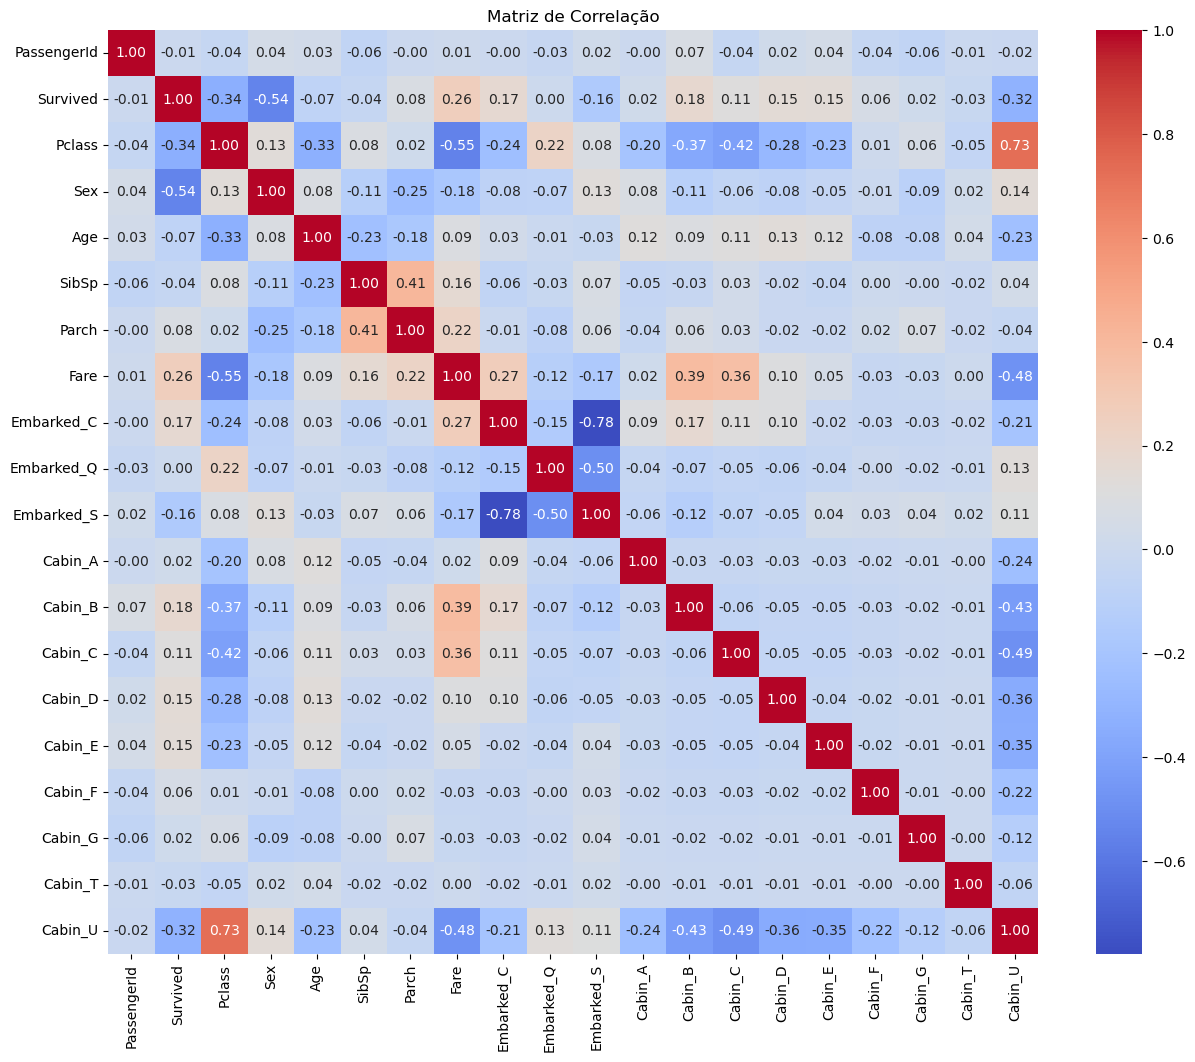

In [ ]:
# Verificação da correlação entre as variáveis da base de treino
var_corr = train_df.corr()

# Exibição da matriz de correlação
plt.figure(figsize=(15, 12))
sns.heatmap(var_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação')
plt.show()

A análise da matriz de correlação linear permitiu identificar associações relevantes entre as variáveis preditoras e a variável alvo (`Survived`), fornecendo uma primeira visão sobre quais características dos passageiros apresentam maior relação com a sobrevivência.

Os principais pontos observados foram:
- **Gênero** (`Sex`): apresentou a correlação mais forte com a sobrevivência (-0,54). O sinal negativo está relacionado à codificação utilizada para a variável e indica uma forte associação entre gênero e sobrevivência. Esse resultado é consistente com os registros históricos do desastre, nos quais mulheres apresentaram maiores taxas de sobrevivência.
- **Classe socioeconômica** (`Pclass`): apresentou correlação negativa relevante (-0,34). Como a variável é codificada de forma ordinal, valores maiores representam classes inferiores, indicando uma associação entre a classe do passageiro e sua probabilidade de sobrevivência.
- **Ausência de cabine identificada** (`Cabin_U`): apresentou correlação negativa de -0,32 com `Survived` e forte correlação de 0,73 com `Pclass`. Esse resultado sugere que a ausência de informação sobre a cabine pode estar funcionando como um indicador indireto das características socioeconômicas dos passageiros, especialmente por sua associação com passageiros de classes inferiores. Portanto, `Cabin_U` deve ser interpretada como uma variável relacionada à disponibilidade/ausência da informação de cabine, e não diretamente como uma medida de luxo.
- **Tarifa** (`Fare`) **e cabines de classes superiores**: `Fare` apresentou correlação positiva moderada (0,26), enquanto algumas categorias de cabine, como `Cabin_B` (0,18), `Cabin_D` (0,15) e `Cabin_E` (0,15), também apresentaram associações positivas com a sobrevivência. Esses resultados são compatíveis com a relação existente entre tarifa, localização da cabine e classe socioeconômica.
- **Variáveis com baixa correlação linear**: `PassengerId`, `Age` e `Embarked_Q` apresentaram correlações próximas de zero ou de baixa magnitude. Entretanto, uma baixa correlação linear não significa necessariamente que essas variáveis sejam irrelevantes para a modelagem. Uma variável pode apresentar relações não lineares ou interações com outras características que não sejam capturadas pela correlação de Pearson. Por esse motivo, sua utilidade será verificada também durante a etapa de modelagem.

A matriz de correlação também revelou relações importantes entre algumas variáveis preditoras. Um exemplo é a forte correlação entre `Pclass` e `Cabin_U` (0,73), indicando que essas variáveis carregam informações parcialmente relacionadas. Esse aspecto será considerado durante a construção e avaliação dos modelos.

**Estratégia de Modelagem**

Com base nesses resultados, serão desenvolvidos dois cenários de modelagem para comparar o desempenho dos algoritmos.

**1. Cenário completo**

Será utilizado o conjunto completo de variáveis preditoras após o tratamento dos dados, incluindo aquelas que apresentaram baixa correlação linear com `Survived`.

O objetivo é avaliar a capacidade dos modelos de utilizar diferentes características simultaneamente e verificar se variáveis com baixa associação linear individual podem contribuir para a previsão por meio de relações não lineares ou interações.

**2. Cenário selecionado**

Será utilizado um conjunto reduzido de variáveis, priorizando aquelas que apresentaram maior associação com `Survived` e possuem justificativa teórica relevante, como `Sex`, `Pclass`, `Fare` e as principais categorias de `Cabin`.

O objetivo é verificar se a redução das variáveis pode diminuir informações pouco relevantes ou redundantes e, consequentemente, melhorar a capacidade de generalização dos modelos.

A comparação entre os dois cenários permitirá testar empiricamente a hipótese de que um conjunto mais enxuto de variáveis pode apresentar melhor desempenho. No entanto, a seleção não será baseada exclusivamente na correlação linear, pois os modelos podem identificar padrões que não são necessariamente evidenciados pela matriz de correlação.

Dessa forma, a definição do conjunto de variáveis será validada posteriormente por meio das métricas de desempenho dos modelos e da validação cruzada, permitindo avaliar não apenas a associação estatística individual das variáveis, mas também sua contribuição efetiva para a capacidade preditiva.

### E) Separação das variáveis dependentes (Y) e independentes (X) para o desenvolvimento de cenários completos e selecionados no conjunto de treino e teste

In [ ]:
# Separação das variáveis completas
X_train_complet = train_df.drop(columns='Survived', axis=1)
X_test_complet = teste_df
y_train = train_df['Survived']

# Separação das variáveis selecionadas
# Definição das variáveis que serão utilizadas
var_select = ['Sex', 'Pclass', 'Fare', 'Cabin_U', 'Cabin_B', 'Embarked_C',
              'Embarked_S', 'Cabin_D', 'Cabin_E', 'Cabin_C'] 
X_train_select = train_df[var_select]
X_test_select = train_df[var_select]

In [ ]:
# Verificação da divisão "X_train_complet"
X_train_complet

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Cabin_A,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_T,Cabin_U
0,1,3,1,22.000000,1,0,7.2500,False,False,True,False,False,False,False,False,False,False,False,True
1,2,1,0,38.000000,1,0,71.2833,True,False,False,False,False,True,False,False,False,False,False,False
2,3,3,0,26.000000,0,0,7.9250,False,False,True,False,False,False,False,False,False,False,False,True
3,4,1,0,35.000000,1,0,53.1000,False,False,True,False,False,True,False,False,False,False,False,False
4,5,3,1,35.000000,0,0,8.0500,False,False,True,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,1,27.000000,0,0,13.0000,False,False,True,False,False,False,False,False,False,False,False,True
887,888,1,0,19.000000,0,0,30.0000,False,False,True,False,True,False,False,False,False,False,False,False
888,889,3,0,29.699118,1,2,23.4500,False,False,True,False,False,False,False,False,False,False,False,True
889,890,1,1,26.000000,0,0,30.0000,True,False,False,False,False,True,False,False,False,False,False,False


In [ ]:
# Verificação da divisão "X_test_complet"
X_test_complet

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S,Cabin_A,Cabin_B,Cabin_C,Cabin_D,Cabin_E,Cabin_F,Cabin_G,Cabin_U
0,892,3,1,34.500000,0,0,7.8292,False,True,False,False,False,False,False,False,False,False,True
1,893,3,0,47.000000,1,0,7.0000,False,False,True,False,False,False,False,False,False,False,True
2,894,2,1,62.000000,0,0,9.6875,False,True,False,False,False,False,False,False,False,False,True
3,895,3,1,27.000000,0,0,8.6625,False,False,True,False,False,False,False,False,False,False,True
4,896,3,0,22.000000,1,1,12.2875,False,False,True,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,1,29.699118,0,0,8.0500,False,False,True,False,False,False,False,False,False,False,True
414,1306,1,0,39.000000,0,0,108.9000,True,False,False,False,False,True,False,False,False,False,False
415,1307,3,1,38.500000,0,0,7.2500,False,False,True,False,False,False,False,False,False,False,True
416,1308,3,1,29.699118,0,0,8.0500,False,False,True,False,False,False,False,False,False,False,True


In [ ]:
# Verificação da divisão "X_train_select"
X_train_select

,Sex,Pclass,Fare,Cabin_U,Cabin_B,Embarked_C,Embarked_S,Cabin_D,Cabin_E,Cabin_C
0,1,3,7.2500,True,False,False,True,False,False,False
1,0,1,71.2833,False,False,True,False,False,False,True
2,0,3,7.9250,True,False,False,True,False,False,False
3,0,1,53.1000,False,False,False,True,False,False,True
4,1,3,8.0500,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...
886,1,2,13.0000,True,False,False,True,False,False,False
887,0,1,30.0000,False,True,False,True,False,False,False
888,0,3,23.4500,True,False,False,True,False,False,False
889,1,1,30.0000,False,False,True,False,False,False,True


In [ ]:
# Verificação da divisão "X_train_select"
X_test_select

,Sex,Pclass,Fare,Cabin_U,Cabin_B,Embarked_C,Embarked_S,Cabin_D,Cabin_E,Cabin_C
0,1,3,7.2500,True,False,False,True,False,False,False
1,0,1,71.2833,False,False,True,False,False,False,True
2,0,3,7.9250,True,False,False,True,False,False,False
3,0,1,53.1000,False,False,False,True,False,False,True
4,1,3,8.0500,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...
886,1,2,13.0000,True,False,False,True,False,False,False
887,0,1,30.0000,False,True,False,True,False,False,False
888,0,3,23.4500,True,False,False,True,False,False,False
889,1,1,30.0000,False,False,True,False,False,False,True


In [ ]:
# Verificação da variável dependente "y_train"
y_train

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64

## 3 - Duelo entre modelos

A escolha dos modelos fundamenta-se no contraste entre duas filosofias matemáticas distintas para classificação binária. O Random Forest foi selecionado por ser um modelo baseado em comitês de árvores de decisão, altamente robusto contra overfitting e capaz de lidar nativamente com dados categóricos e ruídos. Já o SVM (Support Vector Machine) atua de forma geométrica, buscando encontrar o hiperplano ideal de separação com máxima margem entre as classes. Esse duelo permite avaliar qual arquitetura — uma baseada em regras de decisão agrupadas ou outra baseada em fronteiras espaciais complexas — apresenta melhor poder de generalização para os dados do Titanic.

### Random Forest

#### A) Cenário completo

##### Dados desbalanceados e despadronizados

In [154]:
# Inicialização do modelo Random Classifier completo
rf_model_complet_dp = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1)

In [155]:
# Treinamento do modelo na base de treino completo
rf_model_complet_dp.fit(X_train_complet, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [156]:
# Previsão do modelo na base de treino completo
y_rf_train_pred_complet_dp = rf_model_complet_dp.predict(X_train_complet)

In [157]:
# Configuração do Cross Validation, definição do número de folds e modelo com validação cruzada
folds = 5
crossvalidation_complet_dp = KFold(n_splits=folds, shuffle=True, random_state=5)
media_final_complet_dp = cross_val_score(rf_model_complet_dp, X_train_complet, y_train, cv=folds)

In [ ]:
# MELHORAR EXIBIÇÃO...
# Avaliação do modelo preliminar
accuracy_complet_dp = accuracy_score(y_train, y_rf_train_pred_complet_dp)
report_complet_dp = classification_report(y_train, y_rf_train_pred_complet_dp)
confusion_matrix_complet_dp = confusion_matrix(y_train, y_rf_train_pred_complet_dp)
pontuacoes_complet_dp = cross_val_score(rf_model_complet_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp)

print(f'Acurácia do modelo Random Forest: {accuracy_complet_dp:.2f}')
print(f'Relatório de classificação Random Forest: \n {report_complet_dp}')
print(f'Matriz de confusão Random Forest: \n {confusion_matrix_complet_dp}')
print(f'Média das pontuações do cross validation Random Forest: {pontuacoes_complet_dp.mean():.2f}')

Acurácia do modelo Random Forest: 1.00
Relatório de classificação Random Forest: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       549
           1       1.00      1.00      1.00       342

    accuracy                           1.00       891
   macro avg       1.00      1.00      1.00       891
weighted avg       1.00      1.00      1.00       891

Matriz de confusão Random Forest: 
 [[549   0]
 [  0 342]]
Média das pontuações do cross validation Random Forest: 0.81


In [159]:
# Análise da curva AUC-ROC
fpr, tpr, thresholds = roc_curve(y_train, y_rf_train_pred_complet_dp)

# Cálculo da AUC
roc_auc_complet_dp = roc_auc_score(y_train, y_rf_train_pred_complet_dp)
print('AUC: {:.2f}'.format(roc_auc_complet_dp))

AUC: 1.00


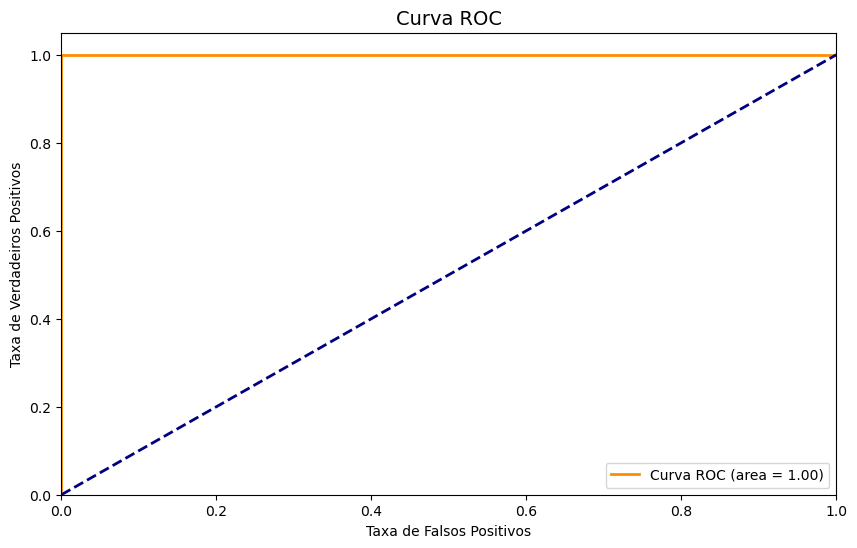

In [160]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_dp)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
Os resultados iniciais do modelo Random Forest treinado com o conjunto de dados completo e hiperparâmetros padrão revelam um cenário de overfitting severo (sobreajuste).

Ao analisar as métricas de validação internas, o modelo atingiu uma Acurácia de 1.00, AUC-ROC de 1.00 e uma matriz de confusão perfeita, sem nenhum erro de classificação dentro do conjunto mapeado. No entanto, o indicador mais realista do real poder de generalização do algoritmo é revelado pela Validação Cruzada (Cross-Validation), que registrou uma média de 0.81.

Essa divergência acentuada (1.00 no treino vs. 0.81 na validação cruzada) ocorre porque, por padrão, o `RandomForestClassifier` não possui limite de profundidade para suas árvores (`max_depth=None`). Como consequência, o algoritmo memorizou perfeitamente os dados de treino, criando ramificações tão profundas que isolaram perfeitamente cada caso, perdendo a capacidade de generalizar de forma eficiente para novos dados do mundo real. Esse comportamento reforça a necessidade crucial do próximo processo do projeto: a tunagem de hiperparâmetros para controlar a complexidade das árvores e estabilizar o modelo.

**Aplicação de hiperparâmetros no Random Forest completo**

In [ ]:
# Definição de hiperparâmetros para testes
param_grid_rf_complet_dp = {
    'n_estimators': [100, 200, 300],     # Quantidade de árvores
    'max_depth': [3, 5, 7, 10],          # Controla a profundidade máxima
    'min_samples_split': [5, 10, 20],   # Número mínimo de amostras para separar um nó
    'min_samples_leaf': [2, 4, 8],   # Número mínimo de amostras que devem ficar em cada folha
    'max_features': ['sqrt', 'log2']    # Quantidade de colunas sorteadas por árvore
}

In [ ]:
# Configuração do Grid Search
grid_search_rf_complet_dp = GridSearchCV(
    estimator=rf_model_complet_dp,
    param_grid=param_grid_rf_complet_dp,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

In [ ]:
# Executando o Grid Search
grid_search_rf_complet_dp.fit(X_train_complet, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': [2, 4, 8],
                         'min_samples_split': [5, 10, 20],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy', verbose=1)

In [ ]:
# Melhores hiperparâmetros
print("Melhores parâmetros:", grid_search_rf_complet_dp.best_params_)
print("Melhor score:", grid_search_rf_complet_dp.best_score_)

Melhores parâmetros: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 200}
Melhor score: 0.8361496453455526


In [179]:
# Treinamento do modelo com os melhores hiperparâmetros
best_rf_completo_dp = grid_search_rf_completo_dp.best_estimator_
best_rf_completo_dp.fit(X_train_complet, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=4, min_samples_split=5,
                       n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
# Previsão do modelo na base de treino completo com os melhores hiperpâmetros
y_rf_train_pred_complet_dp_best = best_rf_completo_dp.predict(X_train_complet)

In [ ]:
# MELHORAR EXIBIÇÃO...
# Avaliação do modelo preliminar com os melhores hiperpâmetros
accuracy_complet_dp_best = accuracy_score(y_train, y_rf_train_pred_complet_dp_best)
report_complet_dp_best = classification_report(y_train, y_rf_train_pred_complet_dp_best)
confusion_matrix_complet_dp_best = confusion_matrix(y_train, y_rf_train_pred_complet_dp_best)
pontuacoes_complet_dp_best = cross_val_score(best_rf_completo_dp, X_train_complet, y_train, cv=crossvalidation_complet_dp)

print(f'Acurácia do modelo Random Forest com os melhores hiperpâmetros: {accuracy_complet_dp_best:.2f}')
print(f'Relatório de classificação Random Forest com os melhores hiperpâmetros: \n {report_complet_dp_best}')
print(f'Matriz de confusão Random Forest com os melhores hiperpâmetros: \n {confusion_matrix_complet_dp_best}')
print(f'Média das pontuações do cross validation Random Forest com os melhores hiperpâmetros: {pontuacoes_complet_dp_best.mean():.2f}')

Acurácia do modelo Random Forest: 0.89
Relatório de classificação Random Forest: 
               precision    recall  f1-score   support

           0       0.87      0.96      0.91       549
           1       0.93      0.76      0.84       342

    accuracy                           0.89       891
   macro avg       0.90      0.86      0.87       891
weighted avg       0.89      0.89      0.88       891

Matriz de confusão Random Forest: 
 [[528  21]
 [ 81 261]]
Média das pontuações do cross validation Random Forest: 0.82


In [182]:
# Análise da curva AUC-ROC com os melhores hiperpâmetros
fpr, tpr, thresholds = roc_curve(y_train, y_rf_train_pred_complet_dp_best)

# Cálculo da AUC
roc_auc_complet_dp_best = roc_auc_score(y_train, y_rf_train_pred_complet_dp_best)
print('AUC: {:.2f}'.format(roc_auc_complet_dp_best))

AUC: 0.86


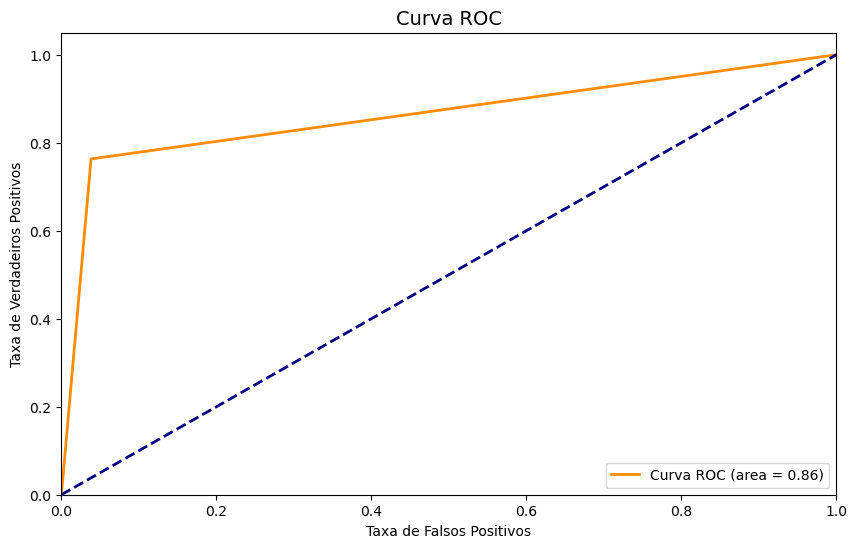

In [183]:
# Gráfico AUC-ROC
plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Curva ROC (area = %0.2f)' % roc_auc_complet_dp_best)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC', fontsize=14)
plt.legend(loc='lower right')
plt.show()

**Análise:** \
A aplicação do GridSearchCV encontrou a combinação ideal de restrições para controlar a complexidade das árvores, selecionando os seguintes parâmetros: max_depth: 10, min_samples_leaf: 4, min_samples_split: 5 e n_estimators: 200. Os impactos práticos dessa otimização refletem-se diretamente nas métricas obtidas:
- **Correção do Overfitting:** A acurácia na base de treino recuou de um valor irreal de 1.00 para 0.89. Essa queda na curva de treino é um excelente indicador técnico: mostra que o modelo parou de apenas memorizar os dados (decorar as linhas) e passou a aprender os padrões estatísticos reais.
- **Estabilidade Estatística:** O score médio do GridSearch atingiu 0.836 (83,6%) e a validação cruzada consolidou-se em 0.82. Como a acurácia de treino (0.89) ficou muito mais próxima da validação (0.82), o modelo demonstra excelente estabilidade e um poder de generalização muito superior para os dados de teste inéditos do Kaggle.
- **Métricas por Classe (F1-Score):** O modelo obteve um desempenho formidável na predição de não-sobreviventes (Classe 0), com F1-Score de 0.91 e Recall de 0.96 (errando apenas 21 passageiros). Para a classe de sobreviventes (Classe 1), o modelo manteve uma alta precisão de 0.93, embora com um Recall ligeiramente menor de 0.76 (81 falsos negativos), resultando em um F1-Score equilibrado de 0.84.
- **Análise da Curva ROC (AUC = 0.86):** A Área Sob a Curva (AUC) de 0.86 confirma graficamente a forte capacidade discriminatória do modelo otimizado. O gráfico demonstra que o algoritmo possui uma alta taxa de verdadeiros positivos logo no início, mantendo uma taxa controlada e baixa de falsos positivos.

##### Dados balanceados e padronizados

#### B) Cenário selecionado

##### Dados desbalanceados e despadronizados

##### Dados balanceados e padronizados

### SVM

#### A) Cenário completo

#### B) Cenário selecionado